# 02 · Etiquetado semiautomático y partición entrenamiento/prueba

Corresponde a las **secciones 3 (Etiquetado) y 6 (División de datos)** del protocolo.

### ¿Por qué semiautomático?
El protocolo indica un etiquetado manual, pero leer y etiquetar **~15,000 reseñas** a mano no es viable para el equipo.
Por eso usamos un procedimiento en dos partes:

1. **Reglas léxicas** (`reglas_etiquetado.py`): listas editables de palabras y frases en inglés que indican un problema de
   **envío** (*never arrived, arrived damaged, box was crushed, wrong item, lost in transit...*) o de **producto**
   (*broke, defective, stopped working, flimsy, leaks, cracked, rust, smell, fell apart, doesn't fit...*).
   Se manejan negaciones (*"no leaks"* no es un defecto) y los **elogios al envío** (*"fast shipping"*) no cuentan como problema.
2. **Validación manual**: se exporta una muestra de la partición de **prueba** (`datos/muestra_validacion.csv`) para
   etiquetarla a mano y medir qué tanto coinciden las reglas con una persona (notebook 09).

### Prioridad cuando una reseña cumple varias reglas: **Envío > Producto > Sentimiento**
- **Envío primero:** es la clase más rara y la más accionable para logística; además, cuando algo llega roto por el transporte,
  la reseña casi siempre usa también palabras de producto (*broken, cracked*). Si Producto tuviera prioridad, los daños de
  transporte nunca se detectarían.
- **Producto después:** un defecto concreto es más informativo que una opinión general.
- **Sentimiento** es la clase por defecto: la reseña opina (bien o mal) sin describir un problema específico.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

import utils
import reglas_etiquetado as reglas
from utils import CLASES, SEMILLA, ARCHIVO_LIMPIO, ARCHIVO_ETIQUETADO, ARCHIVO_VALIDACION, RESULTADOS

SALIDA = RESULTADOS / "etiquetado"
SALIDA.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 160)

df = pd.read_csv(ARCHIVO_LIMPIO, encoding="utf-8-sig")
print("Reseñas limpias:", len(df))
print("Patrones fuertes de Envío:", len(reglas.ENVIO_FUERTE))
print("Patrones de elogio al envío (se ignoran):", len(reglas.ENVIO_POSITIVO))
print("Patrones de Producto:", len(reglas.PRODUCTO_FRASES_NEGATIVAS) + len(reglas.PRODUCTO_TERMINOS))

Reseñas limpias: 14826
Patrones fuertes de Envío: 35
Patrones de elogio al envío (se ignoran): 3
Patrones de Producto: 93


## 1. Prueba rápida de las reglas

Antes de aplicarlas a todo el corpus, verificamos su comportamiento con frases de ejemplo, incluyendo casos difíciles
(elogio al envío, negaciones y reseñas con problema de envío **y** de producto).

In [2]:
ejemplos = [
    "The package arrived late and damaged!!!",
    "Fast shipping, great product, love it.",
    "Arrived quickly and well packaged. The handle broke after two weeks.",
    "No leaks at all, works great.",
    "The box was crushed and the glass arrived shattered.",
    "Doesn't work. Total junk.",
    "Love it! Best purchase ever.",
    "It's ok, nothing special for the price.",
]
pd.DataFrame([(e, *reglas.etiquetar_resena(e)) for e in ejemplos],
             columns=["reseña", "etiqueta_reglas", "regla_disparada"])

,reseña,etiqueta_reglas,regla_disparada
0,The package arrived late and damaged!!!,Envío,envio: arrived late
1,"Fast shipping, great product, love it.",Sentimiento,sin problema específico
2,Arrived quickly and well packaged. The handle broke after two weeks.,Producto,producto: broke
3,"No leaks at all, works great.",Sentimiento,sin problema específico
4,The box was crushed and the glass arrived shattered.,Envío,envio: arrived shattered
5,Doesn't work. Total junk.,Producto,producto: doesn't work
6,Love it! Best purchase ever.,Sentimiento,sin problema específico
7,"It's ok, nothing special for the price.",Sentimiento,sin problema específico


## 2. Aplicar las reglas a todo el corpus

Guardamos dos columnas:
- `etiqueta_reglas`: la etiqueta que usarán los modelos como variable objetivo.
- `regla_disparada`: el fragmento de texto que activó la regla (sirve para auditar cada decisión).

La columna original `polarity` se conserva **solo para análisis** (por ejemplo, para ver si las reseñas de 3 estrellas son más difíciles).

,reseñas,porcentaje
etiqueta_reglas,,
Envío,342,2.31
Producto,5767,38.90
Sentimiento,8717,58.80


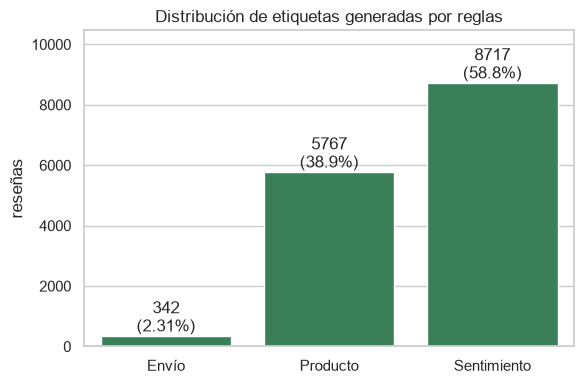

In [3]:
resultado = df["text"].apply(reglas.etiquetar_resena)
df["etiqueta_reglas"] = resultado.str[0]
df["regla_disparada"] = resultado.str[1]

distribucion = (df["etiqueta_reglas"].value_counts().reindex(CLASES).rename("reseñas").to_frame())
distribucion["porcentaje"] = (100 * distribucion["reseñas"] / len(df)).round(2)
distribucion.to_csv(SALIDA / "distribucion_etiquetas.csv", encoding="utf-8-sig")
display(distribucion)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=distribucion.index, y=distribucion["reseñas"], ax=ax, color="seagreen")
for i, v in enumerate(distribucion["reseñas"]):
    ax.text(i, v, f"{v}\n({distribucion['porcentaje'].iloc[i]}%)", ha="center", va="bottom")
ax.set_title("Distribución de etiquetas generadas por reglas"); ax.set_xlabel(""); ax.set_ylabel("reseñas")
ax.set_ylim(0, distribucion["reseñas"].max() * 1.2)
fig.tight_layout(); fig.savefig(SALIDA / "distribucion_etiquetas.png", dpi=120); plt.show()

## 3. Etiquetas vs. polaridad (estrellas)

Este cruce muestra por qué las estrellas son un criterio vago: hay reseñas positivas que mencionan defectos y reseñas
negativas que no describen ningún problema concreto. Las reseñas **neutrales (3 estrellas)** se reparten entre las tres etiquetas.

polarity,negative,neutral,positive
etiqueta_reglas,,,
Envío,195,120,27
Producto,2804,2305,658
Sentimiento,1948,2527,4242


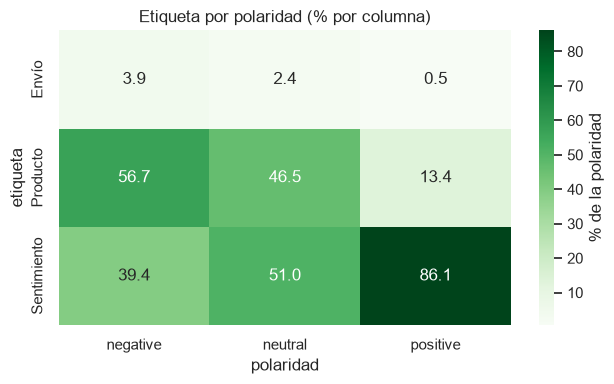

In [4]:
cruce = pd.crosstab(df["etiqueta_reglas"], df["polarity"]).reindex(index=CLASES, columns=["negative", "neutral", "positive"])
cruce_pct = (100 * cruce / cruce.sum(axis=0)).round(1)  # % dentro de cada polaridad
cruce.to_csv(SALIDA / "cruce_etiqueta_polaridad.csv", encoding="utf-8-sig")
display(cruce)

fig, ax = plt.subplots(figsize=(6.5, 4))
sns.heatmap(cruce_pct, annot=True, fmt=".1f", cmap="Greens", cbar_kws={"label": "% de la polaridad"}, ax=ax)
ax.set_title("Etiqueta por polaridad (% por columna)"); ax.set_xlabel("polaridad"); ax.set_ylabel("etiqueta")
fig.tight_layout(); fig.savefig(SALIDA / "cruce_etiqueta_polaridad.png", dpi=120); plt.show()

## 4. Ejemplos y reglas más frecuentes por etiqueta

In [5]:
for etiqueta in CLASES:
    print(f"===== {etiqueta} =====")
    muestra = df[df["etiqueta_reglas"] == etiqueta].sample(3, random_state=SEMILLA)
    for _, fila in muestra.iterrows():
        texto = fila["text"].replace("<br />", " ")[:220]
        print(f"[{int(fila['rating'])}★] ({fila['regla_disparada']}) {texto}")
    print()

===== Envío =====
[3★] (envio: never received) Not the fairest of them all. I need this product for a small bathroom.  The brown color and price are fair.  I am still waiting for it. UPDATE 2023 Again this mirror looks awesome and from reviews of people it was as des
[1★] (envio: was delivered broken) One Star. Was delivered broken in about 6 pieces. wasn't even worth sending back ;(
[1★] (envio: came broken) This is so cute! However mine came broken! .... This is so cute ! However mine came broken ! NO head ! Ugh

===== Producto =====
[3★] (producto: cheaply made) Cheaply made.. This is very cheaply made.  I would recommend spending a little more money and getting a higher quality unit.
[3★] (producto: doesn't stay) The cup is not secure, it will fall out on the floor when grinding. I don't know why they couldn't put some magnet/anti-slip pad on that cup, but it doesn't stay in when grinding.  I have to hold it there.  It defeats th
[1★] (producto: useless) Better products elsewhere -

In [6]:
frecuentes = {}
for etiqueta in ["Envío", "Producto"]:
    conteo = df.loc[df["etiqueta_reglas"] == etiqueta, "regla_disparada"].value_counts().head(15)
    frecuentes[etiqueta] = [f"{k} ({v})" for k, v in conteo.items()]
frecuentes = pd.DataFrame(frecuentes)
frecuentes.to_csv(SALIDA / "reglas_mas_frecuentes.csv", index=False, encoding="utf-8-sig")
frecuentes

,Envío,Producto
0,envio: arrived broken (31),producto: flimsy (245)
1,envio: came broken (19),producto: broke (195)
2,envio: arrived damaged (12),producto: too small (177)
3,envio: came damaged (9),producto: smell (167)
4,envio: arrived bent (6),producto: broken (128)
5,envio: arrived ... missing (6),producto: break (116)
6,envio: not what i ordered (4),producto: doesn't work (110)
7,envio: poor packaging (4),producto: didn't work (110)
8,envio: came cracked (4),producto: poor quality (105)
9,envio: never received (4),producto: cheaply made (98)


## 5. Desbalance de clases

La clase **Envío** es claramente minoritaria (ver tabla anterior). **No se elimina**, porque detectar problemas de envío es
uno de los objetivos del proyecto. Para manejar el desbalance:

- **F1 macro** es la métrica principal (promedia las tres clases con el mismo peso, así que Envío cuenta igual que las demás).
- `class_weight="balanced"` en **SVM** y **Random Forest**.
- `fit_prior=False` en **Naive Bayes** (no favorece a la clase mayoritaria por su frecuencia).
- **KNN** no admite pesos por clase; se prueba `weights="distance"` en la búsqueda de hiperparámetros.
- En el notebook 08 se compara además una versión **balanceada por submuestreo** del conjunto de entrenamiento.

## 6. Partición 80 % entrenamiento / 20 % prueba

La división es **estratificada** por `etiqueta_reglas` (las tres clases quedan en la misma proporción en ambos conjuntos)
y usa `random_state=42`. Se guarda en la columna `particion` para que **todos** los notebooks usen exactamente la misma división.
La validación cruzada de 5 pliegues se hará después **solo sobre entrenamiento**.

In [7]:
idx_entrenamiento, idx_prueba = train_test_split(
    df.index, test_size=0.20, stratify=df["etiqueta_reglas"], random_state=SEMILLA)
df["particion"] = "entrenamiento"
df.loc[idx_prueba, "particion"] = "prueba"

proporciones = pd.crosstab(df["etiqueta_reglas"], df["particion"]).reindex(CLASES)
proporciones["% entrenamiento"] = (100 * proporciones["entrenamiento"] / proporciones["entrenamiento"].sum()).round(2)
proporciones["% prueba"] = (100 * proporciones["prueba"] / proporciones["prueba"].sum()).round(2)
proporciones.loc["Total"] = [proporciones["entrenamiento"].sum(), proporciones["prueba"].sum(), 100.0, 100.0]
proporciones.to_csv(SALIDA / "particion.csv", encoding="utf-8-sig")
display(proporciones)

df.to_csv(ARCHIVO_ETIQUETADO, index=False, encoding="utf-8-sig")
print("Guardado:", ARCHIVO_ETIQUETADO.relative_to(utils.BASE))

particion,entrenamiento,prueba,% entrenamiento,% prueba
etiqueta_reglas,,,,
Envío,274,68,2.31,2.29
Producto,4613,1154,38.90,38.91
Sentimiento,6973,1744,58.79,58.80
Total,11860,2966,100.00,100.00


Guardado: datos\resenas_etiquetadas.csv


## 7. Muestra para validación manual (subconjunto "oro")

Se toman hasta **150 reseñas por etiqueta** (o las que haya) **de la partición de prueba**, es decir, reseñas que ningún modelo
vio durante el entrenamiento. El archivo **no muestra** la etiqueta de las reglas ni las estrellas para no sesgar a quien etiqueta.

**Qué hacer:** abrir `datos/muestra_validacion.csv` (Excel o Google Sheets), leer cada reseña y escribir en `etiqueta_manual`
una de: `Producto`, `Envío` o `Sentimiento` (también se aceptan `P`, `E`, `S`). Después correr el notebook `09_validacion_manual.ipynb`.

> Por seguridad, si el archivo ya existe y tiene etiquetas escritas, **no se sobrescribe**: se guarda una muestra nueva con otro nombre.

In [8]:
prueba = df[df["particion"] == "prueba"]
partes = []
for etiqueta in CLASES:
    grupo = prueba[prueba["etiqueta_reglas"] == etiqueta]
    partes.append(grupo.sample(min(150, len(grupo)), random_state=SEMILLA))
muestra = pd.concat(partes).sample(frac=1, random_state=SEMILLA)  # se revuelve el orden
print("Reseñas en la muestra por etiqueta de reglas (información oculta en el CSV):")
print(muestra["etiqueta_reglas"].value_counts().reindex(CLASES))

muestra_csv = pd.DataFrame({
    "id_muestra": range(1, len(muestra) + 1),
    "id": muestra["id"].values,
    "text": muestra["text"].str.replace("<br />", " ", regex=False).values,
    "etiqueta_manual": "",
    "comentario": "",
})

ya_llenada = False
if ARCHIVO_VALIDACION.exists():
    previa = pd.read_csv(ARCHIVO_VALIDACION, encoding="utf-8-sig", keep_default_na=False)
    ya_llenada = previa.get("etiqueta_manual", pd.Series(dtype=str)).astype(str).str.strip().ne("").any()

destino = ARCHIVO_VALIDACION if not ya_llenada else ARCHIVO_VALIDACION.with_name("muestra_validacion_nueva.csv")
if ya_llenada:
    print("\nAVISO: muestra_validacion.csv ya tiene etiquetas manuales; NO se sobrescribe.")
muestra_csv.to_csv(destino, index=False, encoding="utf-8-sig")
print(f"\nGuardado: {destino.relative_to(utils.BASE)} ({len(muestra_csv)} reseñas)")
muestra_csv.head()

Reseñas en la muestra por etiqueta de reglas (información oculta en el CSV):
etiqueta_reglas
Envío           68
Producto       150
Sentimiento    150
Name: count, dtype: int64

Guardado: datos\muestra_validacion.csv (368 reseñas)


,id_muestra,id,text,etiqueta_manual,comentario
0,1,AH2KHTSRTWMIRJ7IHKPBR3IKCKRQ_B08LPWN6TW_1608684149239,"Would not recommend.. It looks nice. However, upon the first washing it has pilled up. So incredibly disappointed as I was expecting better quality from thi...",,
1,2,AFG4L5UV4S7VPEQCXE2DXO5YGM4A_B0BDD5TM5Q_1672278113071,"Underwhelming desk - concerns for longevity. Overall, this desk looks nice but leaves me concerned with its longevity due to flimsy feeling materials. Pros...",,
2,3,AG5FGCIM6PBJX3JNDRKQMITZTIMA_B07R3JRG3N_1579034000384,This is huge! Three feet across!. It comes ready for you to shape it yourself - which will take some time considering the size. It’s heavy and will be a b...,,
3,4,AEDJZTFJDNOW6JDLMBZNK2QBN3GQ_B07N98VP6M_1481885697000,"Lovely. Love these blankets, the colors really pop in my living room. If your dog is allowed on the couch, his nails will pluck the blanket because it is a ...",,
4,5,AGMGNTI5Y7GXQCGZYA2PJQRWI3SA_B07VVHZLLZ_1576516503165,Scratched!. Arrived all scratched !.......,,
